# Part 4 of 6: Test Evaluation, Compute & Error Analysis

COMP7015 Group Project – Topic 1: Plant Disease Classification. This notebook covers Sections 11–13: the final test evaluation of the selected custom CNN, ResNet18 and ViT over three seeds, their compute trade-offs and an error analysis with Grad-CAM.

Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

from plantdisease.config import DATA_CONFIG, SHORT_NAMES, TRAIN_CONFIG, out_path
from plantdisease.data.dataset import prepare
from plantdisease.device import device
from plantdisease.evaluate import (
    inference_cost,
    mean_sd,
    stable_errors,
    training_cost,
)
from plantdisease.experiments import config_of, load_final_models
from plantdisease.gradcam import grad_cam_images
from plantdisease.plots import finish
from plantdisease.predictions import predict_probs
from plantdisease.train import run

# selected on the validation set (notebooks 02, 03)
BEST_CNN, BEST_RESNET, BEST_VIT = load_final_models()
FINAL_MODELS = [BEST_CNN, BEST_RESNET, BEST_VIT]
data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache
y_test, seed0 = data.y_test, TRAIN_CONFIG["seeds"][0]

## 11. Final Test Evaluation (3 Seeds)

The three selected models (best custom CNN and ResNet18 from notebook 02, best ViT strategy from notebook 03) were trained with **3 training seeds** (62, 63, 64) on the same split. Each seed's best-validation checkpoint is evaluated **once** on the held-out test set. We report the **mean ± standard deviation over the seeds**, so a difference between models can be judged against the run-to-run variation. All seeds use the same test photos; the standard deviation does not cover a different choice of test leaves.

In [2]:
for name in FINAL_MODELS:
    run(name, data)  # loads the runs of notebooks 02 and 03

# softmax probabilities on the test set: test_probs[model] is an array (seeds, N, K)
# (cached in OUT_DIR/runs/<run>/preds/)
test_probs = predict_probs(FINAL_MODELS, {"test": data.images[data.test_idx]})["test"]
# predicted classes: test_preds[model] is (seeds, N); [0] is the first seed
test_preds = {name: p.argmax(-1) for name, p in test_probs.items()}

rows = []
for name in FINAL_MODELS:
    for seed, y_pred in zip(TRAIN_CONFIG["seeds"], test_preds[name], strict=True):
        per_class = f1_score(y_test, y_pred, average=None)
        rows.append(
            {
                "model": name,
                "seed": seed,
                "accuracy": accuracy_score(y_test, y_pred),
                "macro_f1": f1_score(y_test, y_pred, average="macro"),
                **{f"F1 {s}": f for s, f in zip(SHORT_NAMES, per_class, strict=True)},
            }
        )
per_seed = pd.DataFrame(rows)
per_seed.to_csv(out_path("test_results_per_seed.csv"), index=False)

metrics = [c for c in per_seed.columns if c not in ("model", "seed")]
test_table = per_seed.groupby("model", sort=False)[metrics].agg(mean_sd)
test_table.to_csv(out_path("test_results.csv"))
print(f"Test set: {len(y_test)} images | mean ± sd over seeds {TRAIN_CONFIG['seeds']}")
test_table

Loaded finished run: SE-CNN lr=3e-3 (seed 62)
Loaded finished run: SE-CNN lr=3e-3 (seed 63)
Loaded finished run: SE-CNN lr=3e-3 (seed 64)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 62)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 63)
Loaded finished run: ResNet18 two-stage + cosine, lr=1e-4 (seed 64)
Loaded finished run: ViT-B/16 full fine-tuning (seed 62)
Loaded finished run: ViT-B/16 full fine-tuning (seed 63)
Loaded finished run: ViT-B/16 full fine-tuning (seed 64)
Test set: 756 images | mean ± sd over seeds [62, 63, 64]


,accuracy,macro_f1,F1 healthy,F1 Bacterial_spot,F1 Early_blight,F1 Late_blight
model,,,,,,
SE-CNN lr=3e-3,0.9841 ± 0.0040,0.9796 ± 0.0050,1.0000 ± 0.0000,0.9984 ± 0.0016,0.9596 ± 0.0105,0.9604 ± 0.0092
"ResNet18 two-stage + cosine, lr=1e-4",0.9885 ± 0.0008,0.9849 ± 0.0010,0.9989 ± 0.0019,1.0000 ± 0.0000,0.9722 ± 0.0018,0.9686 ± 0.0023
ViT-B/16 full fine-tuning,0.9934 ± 0.0013,0.9917 ± 0.0013,1.0000 ± 0.0000,0.9990 ± 0.0018,0.9831 ± 0.0033,0.9846 ± 0.0020


===== SE-CNN lr=3e-3 (seed 62) =====
                precision    recall  f1-score   support

       healthy     1.0000    1.0000    1.0000       148
Bacterial_spot     1.0000    1.0000    1.0000       320
  Early_blight     0.9542    0.9865    0.9701       148
   Late_blight     0.9852    0.9500    0.9673       140

      accuracy                         0.9881       756
     macro avg     0.9849    0.9841    0.9843       756
  weighted avg     0.9883    0.9881    0.9881       756

===== ResNet18 two-stage + cosine, lr=1e-4 (seed 62) =====
                precision    recall  f1-score   support

       healthy     1.0000    1.0000    1.0000       148
Bacterial_spot     1.0000    1.0000    1.0000       320
  Early_blight     0.9542    0.9865    0.9701       148
   Late_blight     0.9852    0.9500    0.9673       140

      accuracy                         0.9881       756
     macro avg     0.9849    0.9841    0.9843       756
  weighted avg     0.9883    0.9881    0.9881       756

==

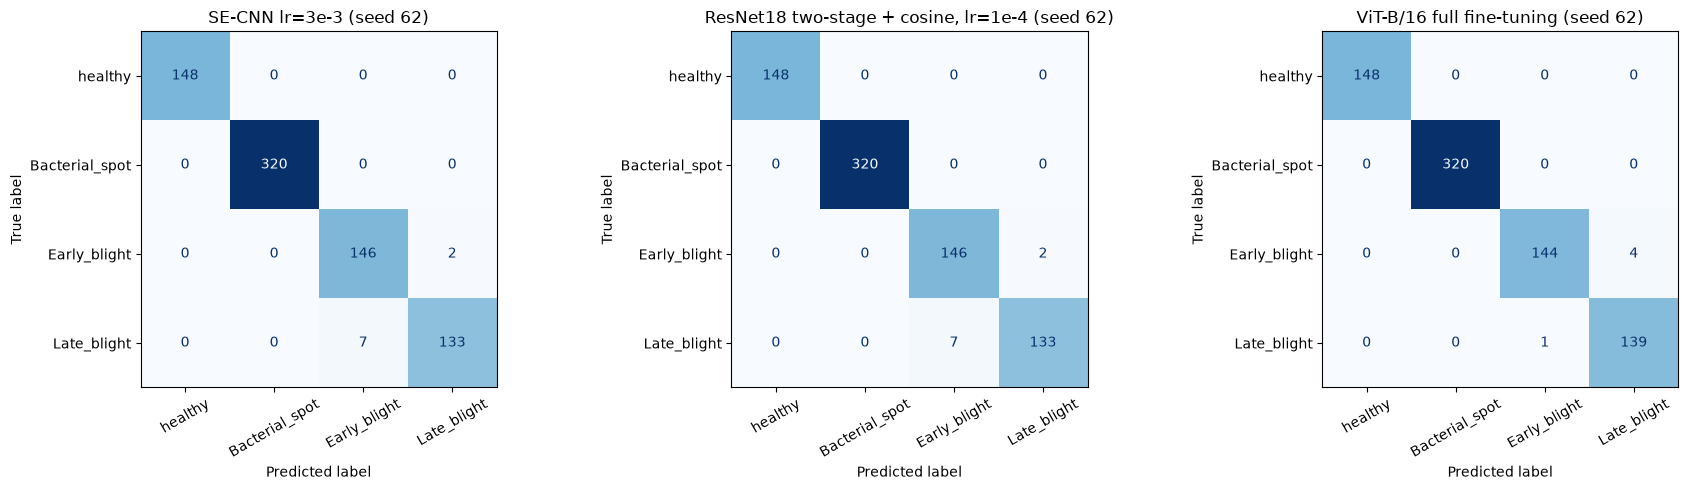

In [3]:
# Detailed report and confusion matrices (first seed)
for name in FINAL_MODELS:
    print(f"===== {name} (seed {seed0}) =====")
    print(
        classification_report(
            y_test,
            test_preds[name][0],
            target_names=SHORT_NAMES,
            digits=4,
        )
    )

fig, axes = plt.subplots(1, len(FINAL_MODELS), figsize=(6 * len(FINAL_MODELS), 5))
for ax, name in zip(axes, FINAL_MODELS, strict=True):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_preds[name][0],
        display_labels=SHORT_NAMES,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=30,
        ax=ax,
    )
    ax.set_title(f"{name} (seed {seed0})")
finish("confusion_matrices.png")

## 12. Compute Trade-offs

Accuracy is not the only criterion. A model for a farmer's phone must be small and fast, and a model that is expensive to train is harder to retrain on new data. For each final model:
- **inference** (checkpoint of the first seed): number of parameters, checkpoint size, latency for a single image and time per image in batches of 64, on the current device after a warm-up;
- **training** (mean over the seeds): trainable parameters in the fine-tuning stage, epochs trained, total training time without validation (device-synchronised) and seconds per epoch.

Training times depend on the number of epochs each model trained (at most CNN 50, ResNet18 16, ViT 15; early stopping can end a run sooner) and on the device.

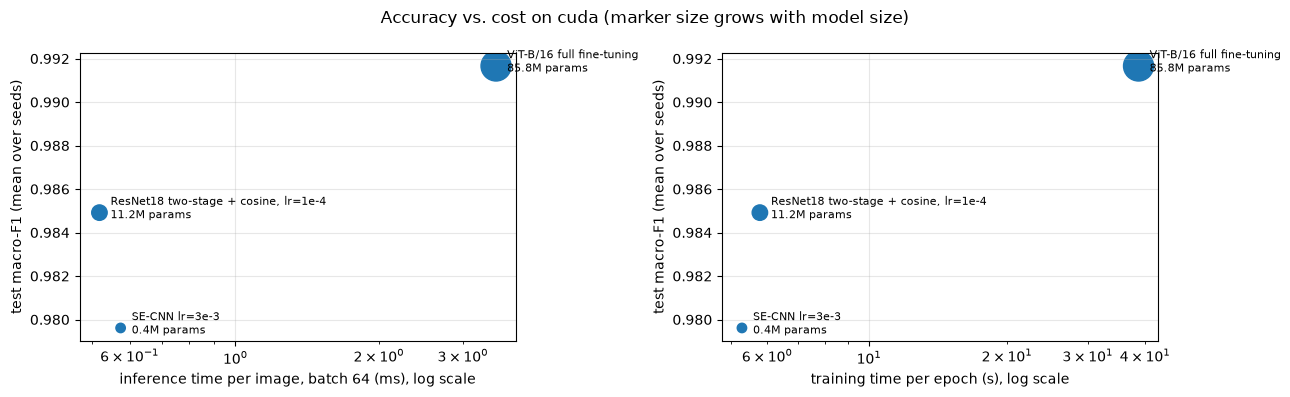

,params (M),size (MB),latency bs=1 (ms),ms/image bs=64,max epochs,trainable params,epochs trained,train time (s),train s/epoch,test macro-F1
model,,,,,,,,,,
SE-CNN lr=3e-3,0.4122,1.6654,1.4871,0.5744,50,412224,50.0 ± 0.0,264.1 ± 2.5,5.2816,0.9796
"ResNet18 two-stage + cosine, lr=1e-4",11.1786,44.7866,3.5158,0.5185,20,11178564,16.3 ± 1.5,94.2 ± 6.3,5.7795,0.9849
ViT-B/16 full fine-tuning,85.8017,343.2575,7.6871,3.5187,20,85801732,15.3 ± 2.5,595.3 ± 116.4,38.6919,0.9917


In [4]:
rows = []
for name in FINAL_MODELS:
    rows.append(
        {
            "model": name,
            **inference_cost(name),
            "max epochs": config_of(name).epochs,
            **training_cost(name),
            "test macro-F1": per_seed.loc[per_seed.model == name, "macro_f1"].mean(),
        }
    )
compute = pd.DataFrame(rows).set_index("model")
compute.to_csv(out_path("compute_tradeoffs.csv"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column, label in [
    (axes[0], "ms/image bs=64", "inference time per image, batch 64 (ms)"),
    (axes[1], "train s/epoch", "training time per epoch (s)"),
]:
    ax.scatter(
        compute[column],
        compute["test macro-F1"],
        s=40 + 4 * compute["size (MB)"] ** 0.8,
    )
    for name, r in compute.iterrows():
        ax.annotate(
            f"{name}\n{r['params (M)']:.1f}M params",
            (r[column], r["test macro-F1"]),
            textcoords="offset points",
            xytext=(8, -4),
            fontsize=8,
        )
    ax.set_xscale("log")
    ax.set_xlabel(f"{label}, log scale")
    ax.set_ylabel("test macro-F1 (mean over seeds)")
    ax.grid(alpha=0.3)
fig.suptitle(f"Accuracy vs. cost on {device.type} (marker size grows with model size)")
finish("compute_tradeoffs.png")
compute.round(4)

## 13. Error Analysis

### 13.1 Which classes are confused, how confident are the errors, and are they stable?
We pool the predictions of all seeds and list the most frequent (true → predicted) confusions, and the mean confidence of correct and wrong predictions. Confident errors are more dangerous than uncertain ones, because uncertain predictions could be flagged for a human expert. Following Zhouyang, we also count the test photos that **every seed** misclassifies: stable errors point to hard or mislabelled photos rather than to training randomness.

In [5]:
n_classes = len(DATA_CONFIG["classes"])
for name in FINAL_MODELS:
    preds = test_preds[name]  # (seeds, N)
    conf = test_probs[name].max(-1)  # confidence of every prediction, (seeds, N)
    wrong = preds != y_test
    # errors of all seeds together: confusion matrix without its diagonal
    cm = sum(confusion_matrix(y_test, p, labels=range(n_classes)) for p in preds)
    np.fill_diagonal(cm, 0)
    pairs = sorted(
        (
            (cm[i, j], SHORT_NAMES[i], SHORT_NAMES[j])
            for i in range(n_classes)
            for j in range(n_classes)
            if cm[i, j]
        ),
        reverse=True,
    )
    conf_wrong = conf[wrong].mean() if wrong.any() else float("nan")
    print(
        f"{name}: {cm.sum()} errors over {len(preds)} seeds"
        f" | mean confidence correct {conf[~wrong].mean():.3f}, wrong {conf_wrong:.3f}"
    )
    for count, t, p in pairs[:4]:
        print(f"    {t:15s} -> {p:15s} {count}")

stability = pd.DataFrame(
    {name: stable_errors(test_preds[name], y_test) for name in FINAL_MODELS}
).T
stability.to_csv(out_path("stable_errors.csv"))
display(stability)

SE-CNN lr=3e-3: 36 errors over 3 seeds | mean confidence correct 0.996, wrong 0.769
    Late_blight     -> Early_blight    20
    Early_blight    -> Late_blight     13
    Early_blight    -> Bacterial_spot  3
ResNet18 two-stage + cosine, lr=1e-4: 26 errors over 3 seeds | mean confidence correct 0.999, wrong 0.873
    Late_blight     -> Early_blight    18
    Early_blight    -> Late_blight     7
    Late_blight     -> healthy         1
ViT-B/16 full fine-tuning: 15 errors over 3 seeds | mean confidence correct 0.999, wrong 0.884
    Early_blight    -> Late_blight     9
    Late_blight     -> Early_blight    4
    Bacterial_spot  -> Early_blight    2


,errors per seed,wrong in every seed,wrong at least once
SE-CNN lr=3e-3,"9, 12, 15",6,19
"ResNet18 two-stage + cosine, lr=1e-4","9, 9, 8",4,13
ViT-B/16 full fine-tuning,"5, 4, 6",3,8


### 13.2 The most confident errors

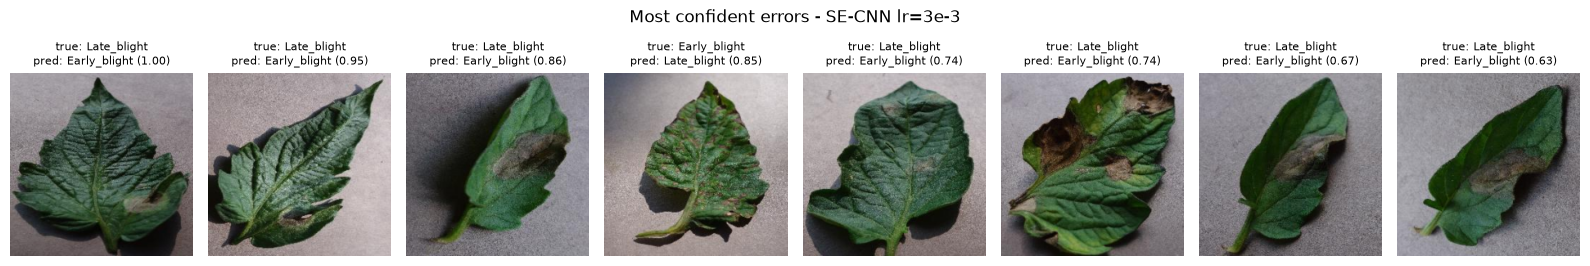

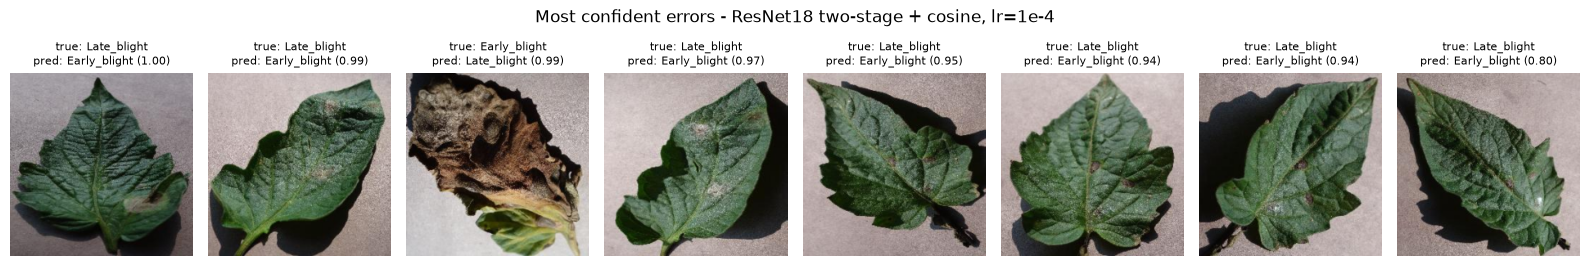

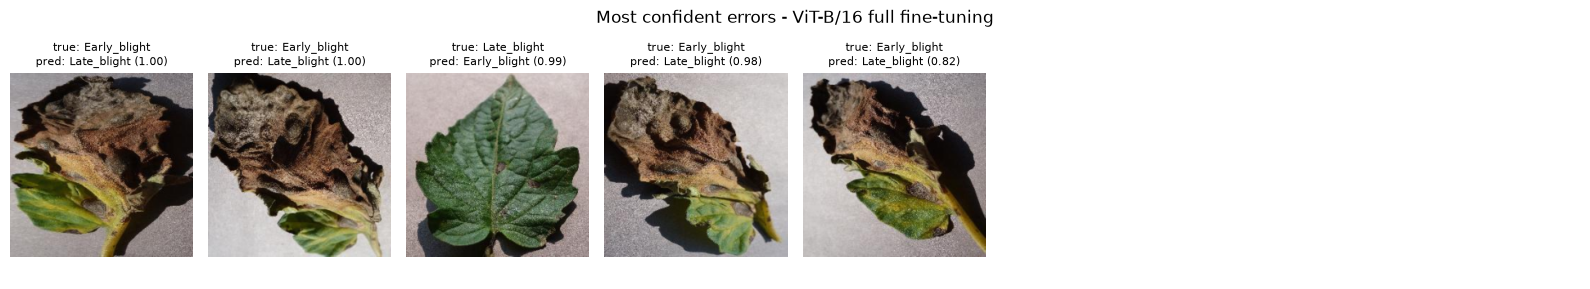

In [6]:
# Misclassified test images (first seed), sorted by confidence (most confident errors first)
for name in FINAL_MODELS:
    probs = test_probs[name][0]
    wrong = np.where(probs.argmax(1) != y_test)[0]
    wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
    if len(wrong) == 0:
        print(f"{name}: no misclassified test images")
        continue
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.9))
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, wrong, strict=False):
        ax.imshow(data.images[data.test_idx[i]].permute(1, 2, 0))
        ax.set_title(
            f"true: {SHORT_NAMES[y_test[i]]}\npred: {SHORT_NAMES[probs[i].argmax()]} ({probs[i].max():.2f})",
            fontsize=8,
        )
    fig.suptitle(f"Most confident errors - {name}")
    finish()

### 13.3 Grad-CAM: where do the CNNs look?
Grad-CAM (Selvaraju et al., 2017) weights the feature maps of the last convolutional layer by the average gradient of the predicted class score. The result is a heat map of the image regions that drove the decision. If a model is right for the right reasons, the heat map lies on the **lesions or mite damage**. If it lies on the **background**, the model may be using a shortcut. We show the same test images (3 correct, up to 3 misclassified by the CNN) for the custom CNN and ResNet18. Grad-CAM needs convolutional feature maps, so the ViT is not shown here. The implementation is `grad_cam` in `plantdisease/evaluate.py`.

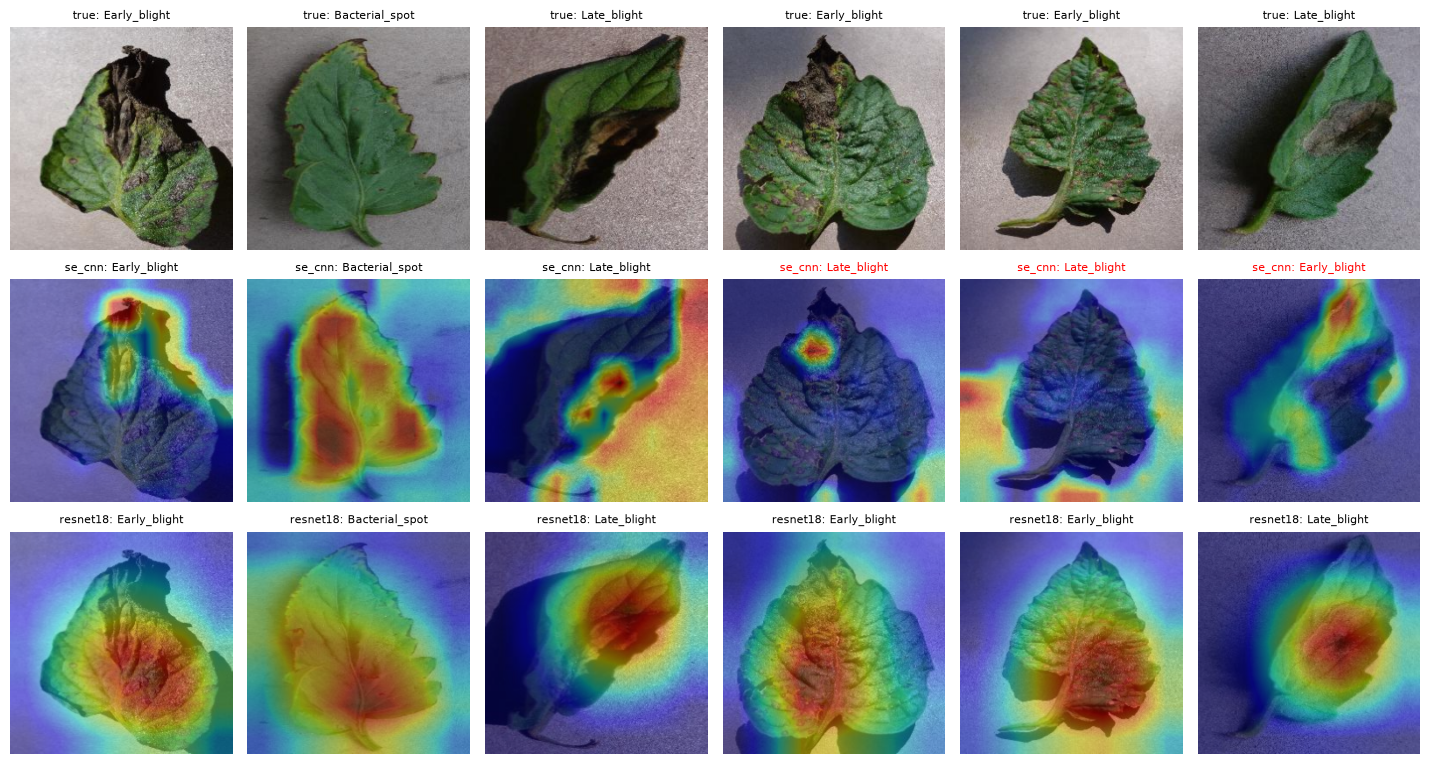

In [7]:
cnn_pred = test_preds[BEST_CNN][0]
rng_cam = np.random.default_rng(0)
examples = np.concatenate(
    [
        rng_cam.choice(np.where(cnn_pred == y_test)[0], 3, replace=False),
        np.where(cnn_pred != y_test)[0][:3],
    ]
)
images = data.images[data.test_idx[examples]]

cam_models = [BEST_CNN, BEST_RESNET]
fig, axes = plt.subplots(
    len(cam_models) + 1,
    len(examples),
    figsize=(2.4 * len(examples), 2.6 * (len(cam_models) + 1)),
    squeeze=False,
)
for col, i in enumerate(examples):
    axes[0, col].imshow(images[col].permute(1, 2, 0))
    axes[0, col].set_title(f"true: {SHORT_NAMES[y_test[i]]}", fontsize=8)
for row, name in enumerate(cam_models, start=1):
    cams = grad_cam_images(name, seed0, images)
    preds = test_preds[name][0]
    for col, i in enumerate(examples):
        axes[row, col].imshow(images[col].permute(1, 2, 0))
        axes[row, col].imshow(cams[col], cmap="jet", alpha=0.45)
        axes[row, col].set_title(
            f"{config_of(name).arch}: {SHORT_NAMES[preds[i]]}",
            fontsize=8,
            color="black" if preds[i] == y_test[i] else "red",
        )
for ax in axes.flat:
    ax.axis("off")
finish("grad_cam.png")